## Epilog EDA
Zur visualisierung und Dokumentation der Ergebnisse der Datananalyse und Kundenkategorisierung werden in diesem Notebook die Kundengruppen und Perks, sowie die Verteilung aufbereitet.

# Zelle 1
Verteilung der Perks (Absolute & Prozentuale Anteile):

Erfolgreich 50,000 Kundenzuweisungen für den Prolog geladen.


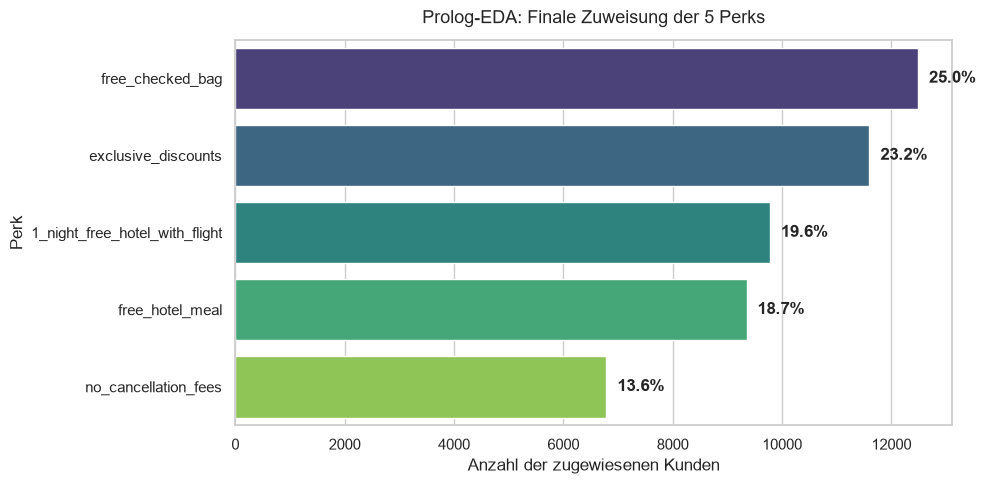

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Design-Settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# 1. Finales Zuordnungs-Artefakt laden
df_perks = pd.read_csv('data/perk_assignments.csv')
df_demo = pd.read_csv('data/traveltide_user_aggregated_eda.csv')

# Zusammenführen von Demographie und Perk-Assignments
df_summary = df_perks.merge(df_demo, on='user_id')

print(f"Erfolgreich {len(df_summary):,} Kundenzuweisungen für den Prolog geladen.")

# 2. Graph 1: Gesamtverteilung der Perks
plt.figure(figsize=(10, 5))
perk_counts = df_summary['assigned_perk'].value_counts()
ax = sns.barplot(x=perk_counts.values, y=perk_counts.index, hue=perk_counts.index, legend=False, palette="viridis")

plt.title("Prolog-EDA: Finale Zuweisung der 5 Perks", fontsize=13, pad=12)
plt.xlabel("Anzahl der zugewiesenen Kunden")
plt.ylabel("Perk")

# Prozentuale Beschriftung hinzufügen
total = len(df_summary)
for p in ax.patches:
    pct = f'{(p.get_width() / total) * 100:.1f}%'
    ax.annotate(pct, (p.get_width() + 200, p.get_y() + p.get_height() / 2), ha='left', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Zelle 2
Perk Aufteilung Kinder / Ohne Kinder

Prolog-EDA: 50,000 Kundenzuweisungen erfolgreich mit Demografie verknüpft.


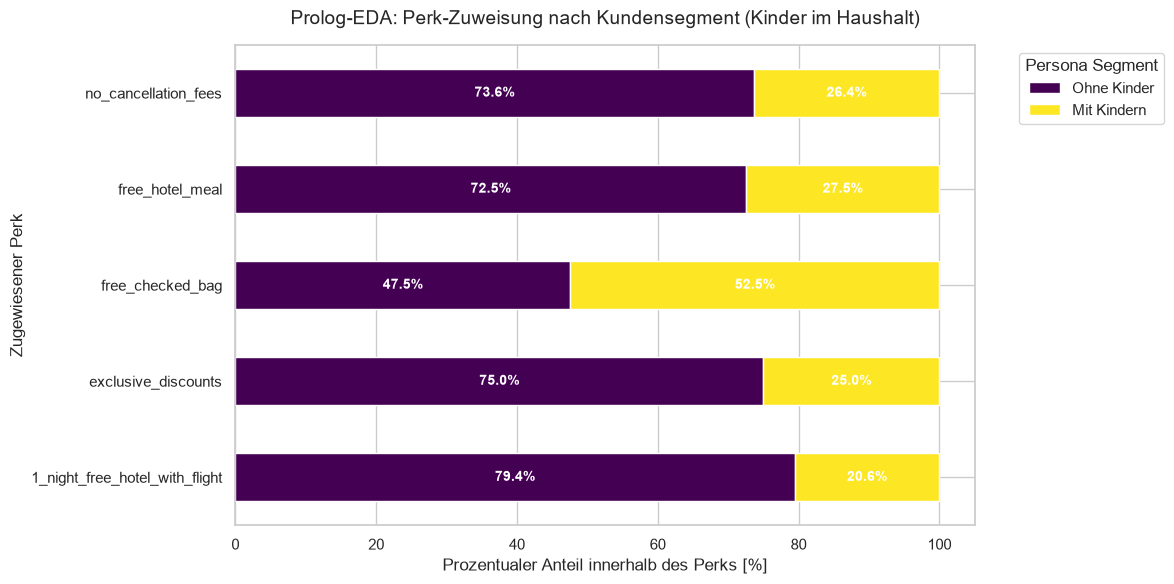

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Design-Einstellungen
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# 1. Daten laden
df_perks = pd.read_csv('data/perk_assignments.csv')
df_demo = pd.read_csv('data/traveltide_user_aggregated_eda.csv')

# 2. Mergen über user_id für den vollen Kontext
df_summary = df_perks.merge(df_demo, on='user_id')

print(f"Prolog-EDA: {len(df_summary):,} Kundenzuweisungen erfolgreich mit Demografie verknüpft.")

# 3. Persona-Analyse: Perk-Verteilung nach Familienstatus (has_children)
ct_children = pd.crosstab(
    df_summary['assigned_perk'], 
    df_summary['has_children'], 
    normalize='index'
) * 100

# Mapping für bessere Lesbarkeit im Plot
ct_children.columns = ['Ohne Kinder', 'Mit Kindern']

# 4. Visualisierung: Gestapeltes Diagramm (Persona Overlap)
ax = ct_children.plot(kind='barh', stacked=True, colormap='viridis', figsize=(12, 6))

plt.title("Prolog-EDA: Perk-Zuweisung nach Kundensegment (Kinder im Haushalt)", fontsize=14, pad=15)
plt.xlabel("Prozentualer Anteil innerhalb des Perks [%]", fontsize=12)
plt.ylabel("Zugewiesener Perk", fontsize=12)
plt.legend(title="Persona Segment", bbox_to_anchor=(1.05, 1), loc='upper left')

# Beschriftung der Prozentwerte in den Balken
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

# Zelle 3
1. Präferenzen nach Staat
2. Präferenzen nach Flughafen


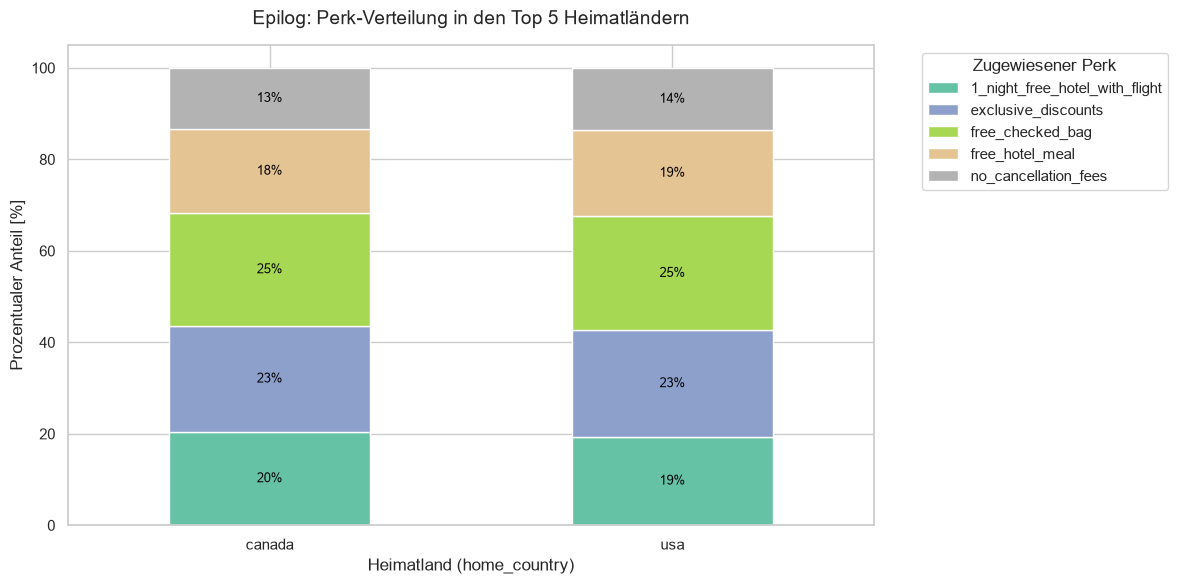

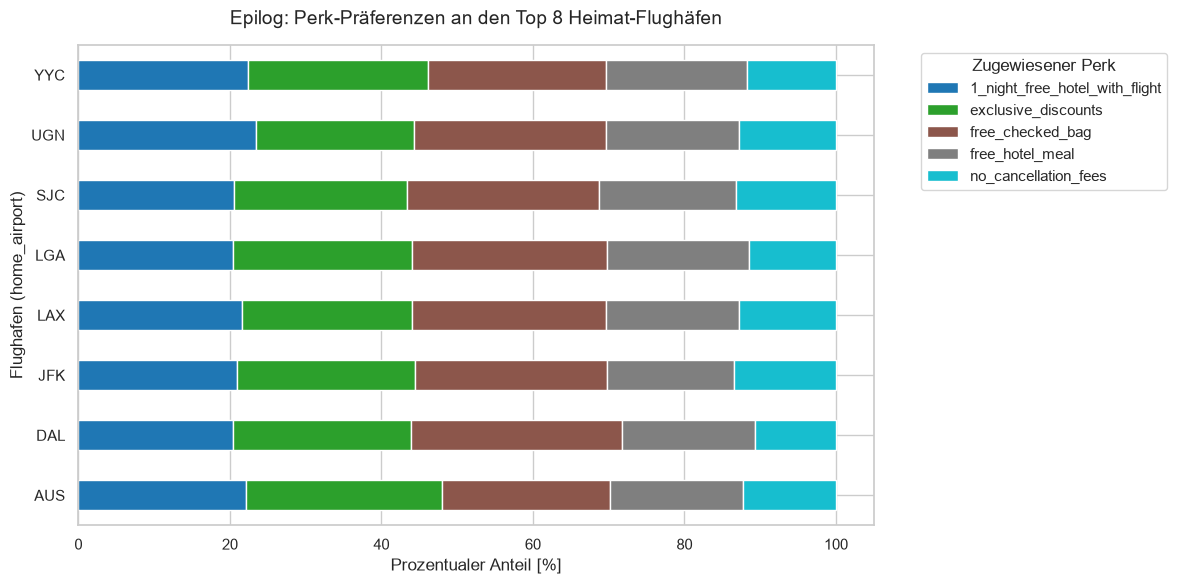

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Design-Settings
sns.set_theme(style="whitegrid")

# 1. Daten laden (Achte auf deinen Pfad)
df_perks = pd.read_csv('data/perk_assignments.csv')
df_demo = pd.read_csv('data/traveltide_user_aggregated_eda.csv')

# Mergen über user_id
df_summary = df_perks.merge(df_demo, on='user_id')

# ---------------------------------------------------------
# ANALYSE 1: Top 5 Länder nach Perk-Verteilung
# ---------------------------------------------------------
top_countries = df_summary['home_country'].value_counts().head(5).index
df_top_countries = df_summary[df_summary['home_country'].isin(top_countries)]

ct_country = pd.crosstab(
    df_top_countries['home_country'], 
    df_top_countries['assigned_perk'], 
    normalize='index'
) * 100

ax1 = ct_country.plot(
    kind='bar', 
    stacked=True, 
    colormap='Set2', 
    figsize=(12, 6)
)

plt.title("Epilog: Perk-Verteilung in den Top 5 Heimatländern", fontsize=14, pad=15)
plt.xlabel("Heimatland (home_country)", fontsize=12)
plt.ylabel("Prozentualer Anteil [%]", fontsize=12)
plt.legend(title="Zugewiesener Perk", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)

# Beschriftung in den Balken
for container in ax1.containers:
    ax1.bar_label(container, fmt='%.0f%%', label_type='center', color='black', fontsize=9)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# ANALYSE 2: Top 8 Flughäfen (Home Airport) nach Perks
# ---------------------------------------------------------
top_airports = df_summary['home_airport'].value_counts().head(8).index
df_top_airports = df_summary[df_summary['home_airport'].isin(top_airports)]

ct_airport = pd.crosstab(
    df_top_airports['home_airport'], 
    df_top_airports['assigned_perk'], 
    normalize='index'
) * 100

ax2 = ct_airport.plot(
    kind='barh', 
    stacked=True, 
    colormap='tab10', 
    figsize=(12, 6)
)

plt.title("Epilog: Perk-Präferenzen an den Top 8 Heimat-Flughäfen", fontsize=14, pad=15)
plt.xlabel("Prozentualer Anteil [%]", fontsize=12)
plt.ylabel("Flughafen (home_airport)", fontsize=12)
plt.legend(title="Zugewiesener Perk", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# Zelle 4
Prüfung der generiten Daten mit Bundestaaten

In [9]:
import pandas as pd

# 1. User & vollständige Airports-Datei lokal laden
df_raw = pd.read_csv('data/travel_tide_cohort_users_export.csv')
df_airports = pd.read_csv('data/airports-complete.csv')

# 2. Directes Merge über IATA
df_merged = df_raw.merge(
    df_airports[['iata_code', 'state_code', 'iso_country']],
    left_on='home_airport',
    right_on='iata_code',
    how='left',
)

# 3. Mismatch-Analyse
matched = df_merged['state_code'].notna().sum()
mismatched = df_merged['state_code'].isna().sum()

print("=== LOKALES MAPPING-ERGEBNIS ===")
print(f"Gesamtanzahl User:           {len(df_raw):,}")
print(
    f"Gematchte User mit State:    {matched:,} ({matched/len(df_raw)*100:.2f}%)"
)
print(
    f"Mismatches (ohne State):     {mismatched:,}"
    f" ({mismatched/len(df_raw)*100:.2f}%)"
)

=== LOKALES MAPPING-ERGEBNIS ===
Gesamtanzahl User:           50,000
Gematchte User mit State:    48,058 (96.12%)
Mismatches (ohne State):     1,942 (3.88%)


# Zelle 5
Wegen 'User-Schwund in der StremlitApp prüfen wir mögliche Ursachen.
Hier direkt einmal das Matching der Use_ids zwischen 'travel_tide_cohort_users_with_states.csv' und 'perk_assignments.csv'

In [15]:
import pandas as pd

# 1. Beide Produktions-CSVs laden
df_perks = pd.read_csv('data/perk_assignments.csv')
df_states = pd.read_csv('data/travel_tide_cohort_users_with_states.csv')

print(f"Zeilen in perk_assignments.csv:                  {len(df_perks):,}")
print(f"Zeilen in travel_tide_cohort_users_with_states: {len(df_states):,}")

# 2. Datentypen & Eindeutigkeit der user_id prüfen
print(
    f"\nEindeutige User-IDs in Perks:  {df_perks['user_id'].nunique():,}"
    f" (Typ: {df_perks['user_id'].dtype})"
)
print(
    f"Eindeutige User-IDs in States: {df_states['user_id'].nunique():,}"
    f" (Typ: {df_states['user_id'].dtype})"
)

# 3. Schnittmenge (Matching) der User-IDs prüfen
set_perks = set(df_perks['user_id'])
set_states = set(df_states['user_id'])

common_users = set_perks.intersection(set_states)
missing_in_states = set_perks - set_states
missing_in_perks = set_states - set_perks

print(f"\n=== MATCHING ERGEBNIS ===")
print(f"User in BEIDEN Dateien (Schnittmenge): {len(common_users):,}")
print(f"User nur in perk_assignments:          {len(missing_in_states):,}")
print(f"User nur in users_with_states:         {len(missing_in_perks):,}")

# 4. Prüfen, wo in users_with_states NaNs/Fehlwerte liegen
print(
    f"\nFehlende 'home_state'-Einträge in users_with_states:"
    f" {df_states['home_state'].isna().sum():,}"
)

# 5. Gegenprobe: Merge-Verhalten simulieren
df_inner = pd.merge(df_perks, df_states, on='user_id', how='inner')
df_left = pd.merge(df_perks, df_states, on='user_id', how='left')

print(f"\nZeilen nach Inner Join: {len(df_inner):,}")
print(f"Zeilen nach Left Join:  {len(df_left):,}")

Zeilen in perk_assignments.csv:                  50,000
Zeilen in travel_tide_cohort_users_with_states: 50,000

Eindeutige User-IDs in Perks:  50,000 (Typ: int64)
Eindeutige User-IDs in States: 50,000 (Typ: int64)

=== MATCHING ERGEBNIS ===
User in BEIDEN Dateien (Schnittmenge): 50,000
User nur in perk_assignments:          0
User nur in users_with_states:         0

Fehlende 'home_state'-Einträge in users_with_states: 1,930

Zeilen nach Inner Join: 50,000
Zeilen nach Left Join:  50,000


# Zelle 6
Lernerfahrung: Aus performancegründen wurde für das Matching mit Flughäfen und Bundesstaaten eine
separat exportierte Datei mit User_ids gezogen, die aufgrund der zufälligen Stichprobe von 50000 aus 330000
50% nicht-übereinstimmende IDs hat (aha!) ;-)

In [12]:
import pandas as pd

# 1. Die beiden Ausgangs-CSVs laden
df_eda_raw = pd.read_csv('data/traveltide_user_aggregates_with_demographics.csv')
df_export_raw = pd.read_csv('data/travel_tide_cohort_users_export.csv')

print(
    f"User in traveltide_user_aggregates_with_demographics: "
    f"{df_eda_raw['user_id'].nunique():,}"
)
print(
    f"User in travel_tide_cohort_users_export:           "
    f"{df_export_raw['user_id'].nunique():,}"
)

# 2. Schnittmenge vergleichen
users_eda = set(df_eda_raw['user_id'])
users_export = set(df_export_raw['user_id'])

common = users_eda.intersection(users_export)

print(f"\n=== URSPRUNGS-COMPARISON ===")
print(f"User in BEIDEN Quell-Dateien:          {len(common):,}")
print(f"User NUR in aggregates_demographics:   {len(users_eda - users_export):,}")
print(f"User NUR in cohort_users_export:       {len(users_export - users_eda):,}")

User in traveltide_user_aggregates_with_demographics: 50,000
User in travel_tide_cohort_users_export:           50,000

=== URSPRUNGS-COMPARISON ===
User in BEIDEN Quell-Dateien:          25,219
User NUR in aggregates_demographics:   24,781
User NUR in cohort_users_export:       24,781
